In [ ]:
import scanpy as sc
import scprep
import pandas as pd
import phate
import anndata

In [ ]:
data_a23 = sc.read_h5ad("../data/A23-290-CP_anndata.h5ad")

<Axes: xlabel='Library size', ylabel='Number of cells'>

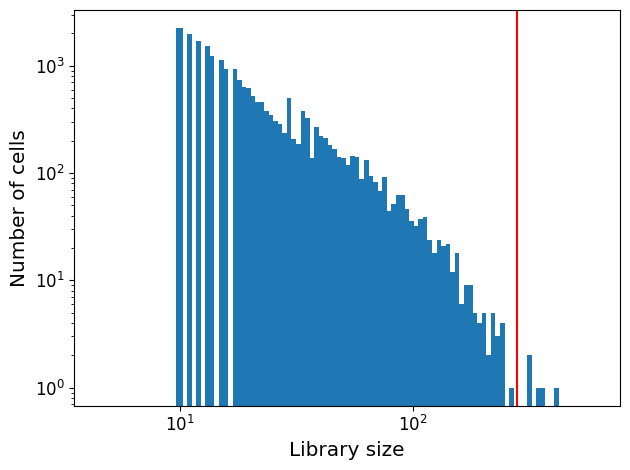

In [109]:
scprep.plot.plot_library_size(data_a23.X, cutoff=280)

In [131]:
data_a23.obsm

AxisArrays with keys: X_spatial, spatial

In [132]:
X_filt = data_a23.X
var_filt = data_a23.var.index
obs_filt = data_a23.obs.index
obsm_X_spatial_filt = data_a23.obsm['X_spatial']
obsm_spatial_filt = data_a23.obsm['spatial']
X_filt, obs_filt, obsm_X_spatial_filt, obsm_spatial_filt = scprep.filter.filter_library_size(X_filt, obs_filt, obsm_X_spatial_filt, obsm_spatial_filt, cutoff=280, keep_cells='below')
X_filt, var_filt = scprep.filter.filter_rare_genes(X_filt, var_filt, min_cells=10)

<Axes: xlabel='Library size', ylabel='Number of cells'>

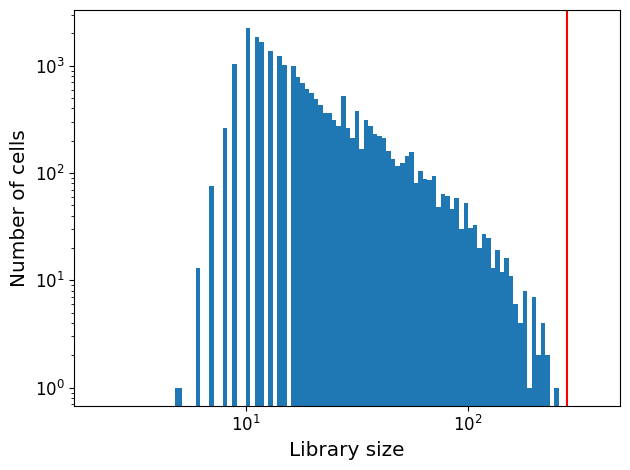

In [111]:
scprep.plot.plot_library_size(X_filt, cutoff=280)

In [112]:
X_filt = scprep.transform.sqrt(X_filt)

<Axes: xlabel='Library size', ylabel='Number of cells'>

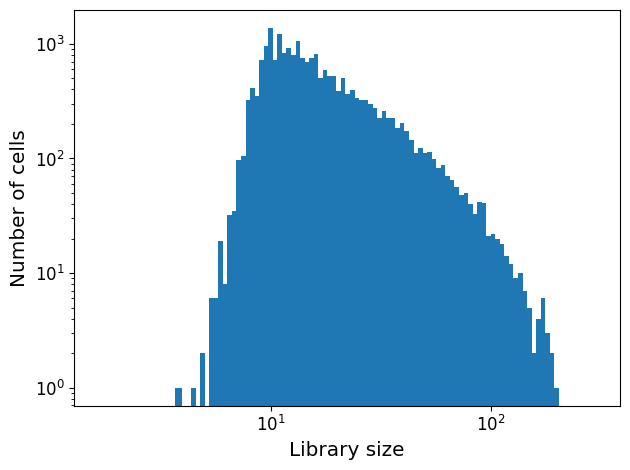

In [113]:
scprep.plot.plot_library_size(X_filt)

In [120]:
adata = anndata.AnnData(X=X_filt, obs=pd.DataFrame(index=obs_filt), var=pd.DataFrame(index=var_filt))
adata.obsm['X_spatial'] = obsm_X_spatial_filt
adata.obsm['spatial'] = obsm_spatial_filt

In [121]:
phate_operator = phate.PHATE()
X_phate = phate_operator.fit_transform(X_filt)
adata.obsm['X_phate'] = X_phate

Calculating PHATE...
  Running PHATE on 21326 observations and 6695 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 1.75 seconds.
    Calculating KNN search...
    Calculated KNN search in 133.10 seconds.
    Calculating affinities...
    Calculated affinities in 25.04 seconds.
  Calculated graph and diffusion operator in 159.99 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 4.75 seconds.
    Calculating KMeans...
    Calculated KMeans in 12.31 seconds.
  Calculated landmark operator in 18.81 seconds.
  Calculating optimal t...
    Automatically selected t = 21
  Calculated optimal t in 7.33 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 2.50 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 7.33 seconds.
Calculated PHATE in 195.98 seconds.


<Axes: title={'center': 'A23-290-CP'}, xlabel='PHATE 1', ylabel='PHATE 2'>

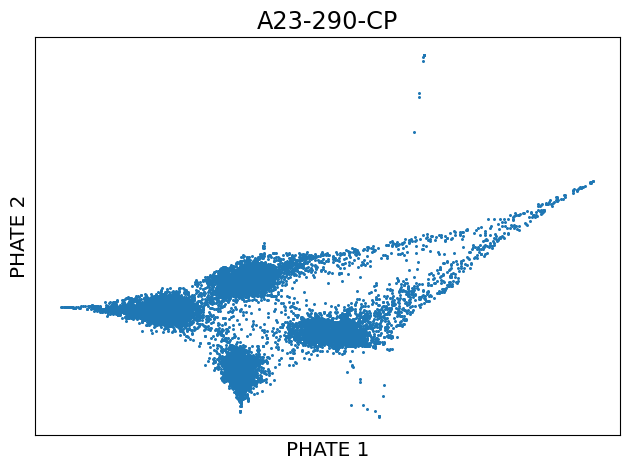

In [122]:
scprep.plot.scatter2d(adata.obsm['X_phate'], ticks=False, label_prefix='PHATE ', title='A23-290-CP')

In [123]:
adata.write_h5ad("../data/A23-290-CP_preprocessed.h5ad")

In [125]:
data_a23.obsm

AxisArrays with keys: X_spatial, spatial

In [135]:
adata.obsm['X_spatial']

array([[-2450.4,  5256.9],
       [-4220. ,  5496. ],
       [-5080.3,  1379. ],
       ...,
       [-1349. ,  5230.9],
       [-2383.3,  3327. ],
       [-4309. ,  3633. ]])

In [136]:
adata.obsm['spatial']

array([[-2450.4,  5256.9],
       [-4220. ,  5496. ],
       [-5080.3,  1379. ],
       ...,
       [-1349. ,  5230.9],
       [-2383.3,  3327. ],
       [-4309. ,  3633. ]])

<Axes: title={'center': 'A23-290-CP'}, xlabel='Spatial 1', ylabel='Spatial 2'>

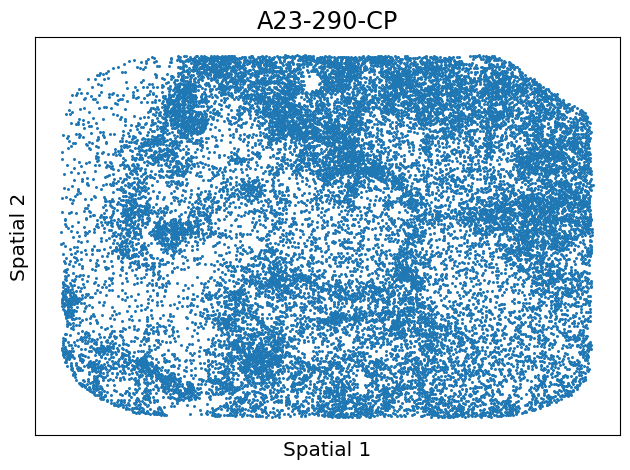

In [137]:
scprep.plot.scatter2d(adata.obsm['X_spatial'], ticks=False, label_prefix='Spatial ', title='A23-290-CP')